In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow
import duckdb

In [2]:
con = duckdb.connect()
con.read_parquet("../Data/Processed/customers_clean.parquet").create_view("customers");

### Unique Customer Analysis


In [44]:
#unique customers id
customers_id = con.sql(""" 
    select customer_id,
            customer_unique_id
    from customers
 """).df()

print(f"number of all customer_id: {customers_id["customer_id"].count()}")
print(f"number of unique customer_id: {customers_id["customer_unique_id"].nunique()}")

display(customers_id["customer_unique_id"].value_counts().head(10).to_frame())

number of all customer_id: 99441
number of unique customer_id: 96096


,count
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
1b6c7548a2a1f9037c1fd3ddfed95f33,7
6469f99c1f9dfae7733b25662e7f1782,7
ca77025e7201e3b30c44b472ff346268,7
47c1a3033b8b77b3ab6e109eb4d5fdf3,6
dc813062e0fc23409cd255f7f53c7074,6
63cfc61cee11cbe306bff5857d00bfe4,6
f0e310a6839dce9de1638e0fe5ab282a,6


**Customer Identifiers: `customer_id` vs. `customer_unique_id`**

- `customer_id`: Identifies a customer record in the dataset and is used to link orders to customer records.
- `customer_unique_id`: Identifies a unique customer across multiple customer records.

A single customer may have multiple `customer_id` values while sharing the same `customer_unique_id`.

**Analytical result:**

- Use `customer_id` to identify customer records and link them to orders.
- Use `customer_unique_id` to estimate the number of unique customers.

Always use `customer_unique_id` when calculating unique customers and repeat purchases.
Counting `customer_id` values as unique people would incorrectly classify repeat customers.

### Geographic Customer Distribution

#### states distribution :

In [ ]:
states = con.sql(""" 
    select customer_state,
            count(*) as customers_count,
            count(*) * 100 / sum(count(*)) over() as customers_percent
    from customers
    group by customer_state
    order by customers_count desc
""").df()

print("Top 10 states with the most customers:")
display(states.head(10))

Top 10 states with the most customers:


,customer_state,customers_count,customers_percent
0,SP,41746,41.980672
1,RJ,12852,12.924247
2,MG,11635,11.700405
3,RS,5466,5.496727
4,PR,5045,5.073360
5,SC,3637,3.657445
6,BA,3380,3.399000
7,DF,2140,2.152030
8,ES,2033,2.044428
9,GO,2020,2.031355


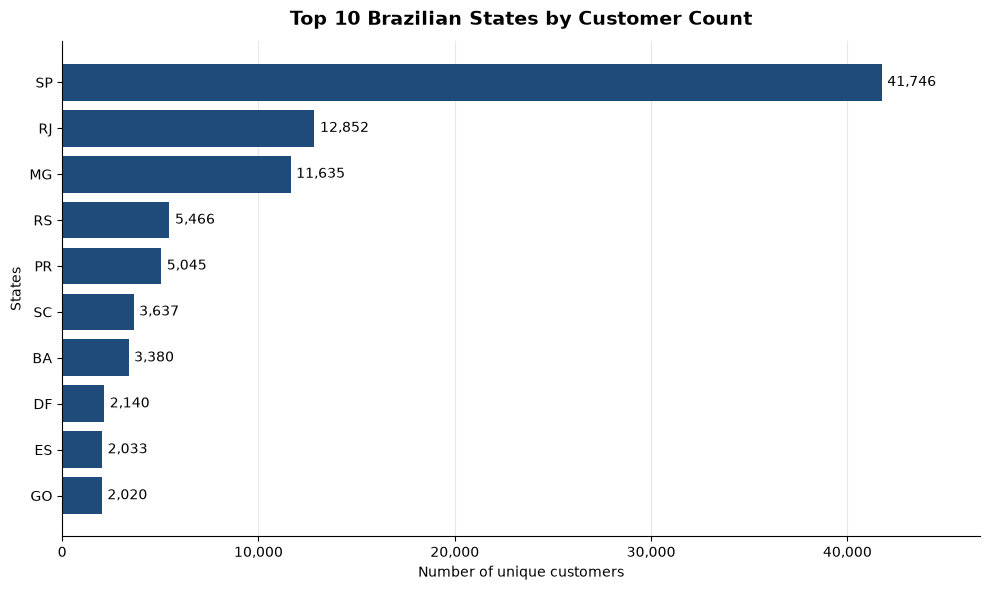

In [ ]:
top_10 = states.head(10)  

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(top_10["customer_state"], top_10["customers_count"], color="#1E4B7A")

# Counts at the end of each bar, with thousands separators
ax.bar_label(bars, labels=[f"{n:,}" for n in top_10["customers_count"]], padding=4, fontsize=10)

ax.invert_yaxis()  # largest bar on top
ax.set_title("Top 10 Brazilian States by Customer Count", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Number of unique customers")
ax.set_ylabel("States")
ax.set_xlim(0, top_10["customers_count"].max() * 1.12)  # room for the top label
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [75]:
#state share
print("share of 5 fisrt states:")
display(states[["customer_state","customers_percent"]].head())
print(f"combined customer share of the five largest states: {sum(states["customers_percent"].head()):.2f}%")

share of 5 fisrt states:


,customer_state,customers_percent
0,SP,41.980672
1,RJ,12.924247
2,MG,11.700405
3,RS,5.496727
4,PR,5.073360


combined customer share of the five largest states: 77.18%


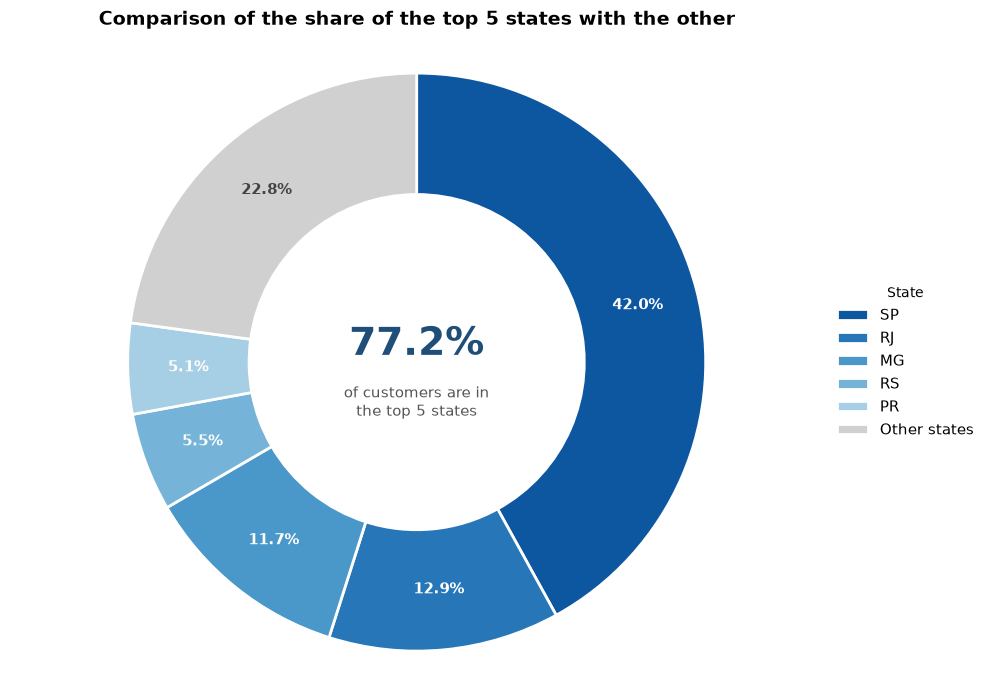

In [39]:
top_5 = states.head(5)  # assumes `states` is sorted by customers_percent, descending

top5_percent = top_5["customers_percent"].sum()
other_percent = 100 - top5_percent

labels = list(top_5["customer_state"]) + ["Other states"]
sizes = list(top_5["customers_percent"]) + [other_percent]

# Blue shades for the top 5 (darkest = largest), gray for the rest
colors = list(plt.cm.Blues_r(np.linspace(0.15, 0.65, 5))) + ["#D0D0D0"]

fig, ax = plt.subplots(figsize=(10, 7))

wedges, texts, autotexts = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.79,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),
)

for i, t in enumerate(autotexts):
    t.set_fontsize(11)
    t.set_fontweight("bold")
    t.set_color("#444444" if i == len(autotexts) - 1 else "white")

# Combined share of the top 5 in the donut center
ax.text(0, 0.06, f"{top5_percent:.1f}%", ha="center", va="center", fontsize=28, fontweight="bold", color="#1F4E79")
ax.text(0, -0.14, "of customers are in\nthe top 5 states", ha="center", va="center", fontsize=11, color="#555555")

ax.legend(
    wedges,
    labels,
    title="State",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
    fontsize=11,
)

ax.set_title(
    f"Comparison of the share of the top 5 states with the other",
    fontsize=14, fontweight="bold", pad=14,
)
ax.axis("equal")

plt.tight_layout()
plt.show()

#### Conclusion :

The geographic analysis reveals a highly concentrated distribution of Olist's unique customers across Brazilian states.

São Paulo (SP) has the largest customer base, with 41,746 unique customers, accounting for approximately 41.98% of all customers. Rio de Janeiro (RJ) and Minas Gerais (MG) rank second and third, with 12,852 and 11,635 customers, respectively. The considerable gap between São Paulo and the other states highlights its dominant position in Olist's customer distribution.

Furthermore, the five states with the highest customer counts (SP, RJ, MG, RS, and PR) collectively account for approximately **77.18% of the total customer base**, while all remaining states represent only 22.82%.

These findings indicate that Olist's customer base is geographically concentrated in a relatively small number of Brazilian states, particularly São Paulo. This concentration should be considered in marketing and market development decisions.

However, customer distribution alone does not determine the business potential or profitability of each state. Further analysis of order volume and purchasing behavior is required to identify regional differences and evaluate potential market expansion opportunities.

#### cities distribution :

In [ ]:
cities = con.sql(""" 
    select customer_city,
            customer_state,
            count(*) as customers_count,
            count(*) * 100 / sum(count(*)) over() as customers_percent
    from customers
    group by customer_state,customer_city
    order by customers_count desc
""").df()

print("top 10 cities with most customers:")
display(cities.head(10))

print(f"total share of top 10 cities: {sum(cities["customers_percent"].head(10)):.2f}%")

top 10 cities with most customers:


,customer_city,customer_state,customers_count,customers_percent
0,sao paulo,SP,15540,15.627357
1,rio de janeiro,RJ,6882,6.920687
2,belo horizonte,MG,2773,2.788588
3,brasilia,DF,2131,2.142979
4,curitiba,PR,1521,1.529550
5,campinas,SP,1444,1.452117
6,porto alegre,RS,1379,1.386752
7,salvador,BA,1245,1.251999
8,guarulhos,SP,1189,1.195684
9,sao bernardo do campo,SP,938,0.943273


total share of top 10 cities: 35.24%


In [90]:
#check top 100 cities distribution
top_100_cities = cities.head(100)

print("number of cities for each state in top 100 cities:")
display(top_100_cities["customer_state"].value_counts().to_frame().head(10))


number of cities for each state in top 100 cities:


,count
customer_state,
SP,47
RJ,10
MG,9
PR,5
RS,5
SC,4
ES,4
BA,2
DF,1


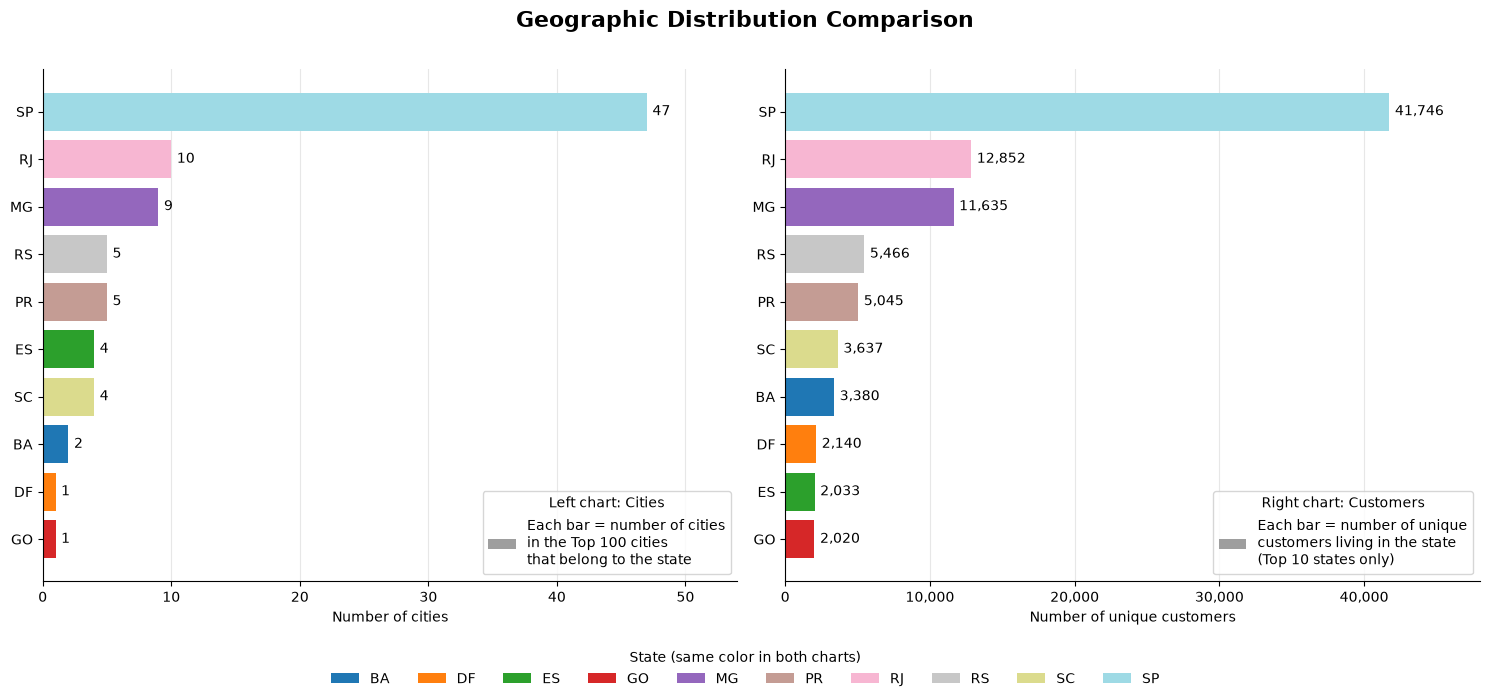

In [99]:

# Prepare data (largest at the bottom after sorting ascending, so it ends up on top in barh)
cities_df = (
    top_100_cities["customer_state"]
    .value_counts()
    .head(10)
    .rename_axis("customer_state")
    .reset_index(name="count")
    .sort_values("count", ascending=True)
)

customers_df = (
    states.head(10)
    .sort_values("customers_count", ascending=True)
)

# One color per state, shared by both charts so the same state is easy to match
all_states = sorted(set(cities_df["customer_state"]) | set(customers_df["customer_state"]))
palette = plt.cm.tab20(np.linspace(0, 1, len(all_states)))
state_color = dict(zip(all_states, palette))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left: state distribution among the top 100 cities
bars_left = axes[0].barh(
    cities_df["customer_state"],
    cities_df["count"],
    color=[state_color[s] for s in cities_df["customer_state"]],
)
axes[0].bar_label(bars_left, padding=4, fontsize=10)
axes[0].set_xlabel("Number of cities")
axes[0].set_xlim(0, cities_df["count"].max() * 1.15)

# Right: top 10 states by customer count
bars_right = axes[1].barh(
    customers_df["customer_state"],
    customers_df["customers_count"],
    color=[state_color[s] for s in customers_df["customer_state"]],
)
axes[1].bar_label(bars_right, labels=[f"{n:,}" for n in customers_df["customers_count"]], padding=4, fontsize=10)
axes[1].set_xlabel("Number of unique customers")
axes[1].set_xlim(0, customers_df["customers_count"].max() * 1.15)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# Shared styling
for ax in axes:
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Geographic Distribution Comparison", fontsize=16, fontweight="bold")

from matplotlib.patches import Patch

# 1) Explanatory legend inside each chart
#    (lower right is empty because the longest bars are at the top)
axes[0].legend(
    handles=[Patch(facecolor="#9E9E9E", label="Each bar = number of cities\nin the Top 100 cities\nthat belong to the state")],
    loc="lower right",
    frameon=True,
    fontsize=10,
    title="Left chart: Cities",
    title_fontsize=10,
)

axes[1].legend(
    handles=[Patch(facecolor="#9E9E9E", label="Each bar = number of unique\ncustomers living in the state\n(Top 10 states only)")],
    loc="lower right",
    frameon=True,
    fontsize=10,
    title="Right chart: Customers",
    title_fontsize=10,
)

# 2) Optional: shared color legend for the states, at the bottom of the figure
state_handles = [Patch(facecolor=state_color[s], label=s) for s in all_states]
fig.legend(
    handles=state_handles,
    title="State (same color in both charts)",
    loc="lower center",
    ncol=len(all_states),
    frameon=False,
    fontsize=10,
)

plt.tight_layout(rect=[0, 0.08, 1, 0.97])  # leave room for the bottom legend
plt.show()

#### Business Conclusion

The geographic analysis reveals a considerable concentration of Olist's customer base in a relatively small number of Brazilian cities and states.

Sao Paulo is the leading city, with 15,540 unique customers, accounting for approximately 15.63% of the total customer base. This is more than twice the number of customers in Rio de Janeiro, which ranks second with 6,882 customers. Overall, the top 10 cities account for approximately 35.24% of all unique customers.

The distribution of the top 100 cities further highlights this geographic concentration. Sao Paulo (SP) accounts for 47 of these cities, followed by Rio de Janeiro (RJ) with 10 and Minas Gerais (MG) with 9. Together, these three states represent 66 of the 100 cities with the highest customer counts.

The comparison chart also reveals a similar pattern between the two geographic indicators. States with more cities represented in the top 100 generally have higher customer counts. Sao Paulo clearly dominates both charts, while Rio de Janeiro and Minas Gerais also maintain leading positions. This suggests that the concentration of customers at the state level is also reflected in the distribution of cities with the highest customer counts.

From a business perspective, these findings indicate that major urban centers, particularly those in Sao Paulo, are important regions for Olist's customer base. Management could consider these areas when planning regional marketing activities, operational capacity, and delivery services.

However, a high customer count or a large number of cities in the top 100 does not necessarily indicate higher profitability or better business performance. Further analysis of order volume, revenue, average order value, and delivery costs is necessary to evaluate the actual business potential of each region.